In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [22]:
df["TotalCharges_num"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

df[df["TotalCharges_num"].isna()][["customerID","tenure","MonthlyCharges","TotalCharges","Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [23]:
df = df.drop(columns="TotalCharges_num")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

print("missing values before:",df["TotalCharges"].isna().sum())
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
print("Missing values after:", df["TotalCharges"].isna().sum())
print(df.shape)

missing values before: 11
Missing values after: 0
(7032, 21)


In [24]:
df = df.drop(columns="customerID")

In [25]:
# Any remaining missing values?
df.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [26]:
# Duplicate rows?
df.duplicated().sum()

np.int64(22)

In [27]:
# See the unique values in each text column
for col in df.select_dtypes(include="object").columns:
    print(col, df[col].unique())

gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <StringArray>
['Month-to-month', 'One year', 'Two year']
Le

C:\Users\vaish\AppData\Local\Temp\ipykernel_25860\4095860940.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


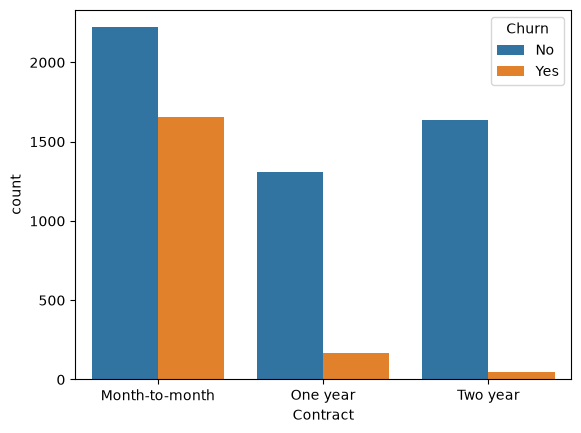

In [28]:
# Churn vs. contract type
sns.countplot(data=df, x="Contract", hue="Churn")
plt.show()

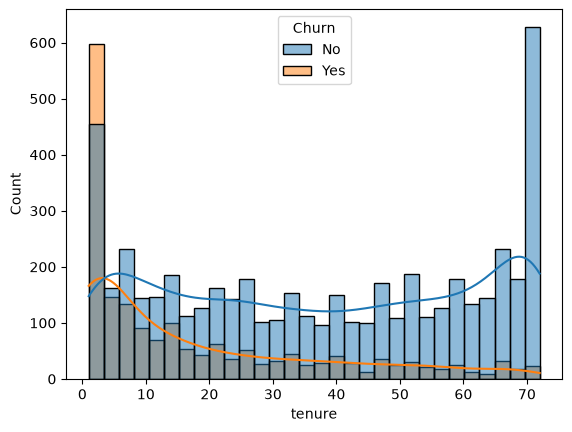

In [29]:
# Tenure distribution for churned vs. retained customers
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True)
plt.show()

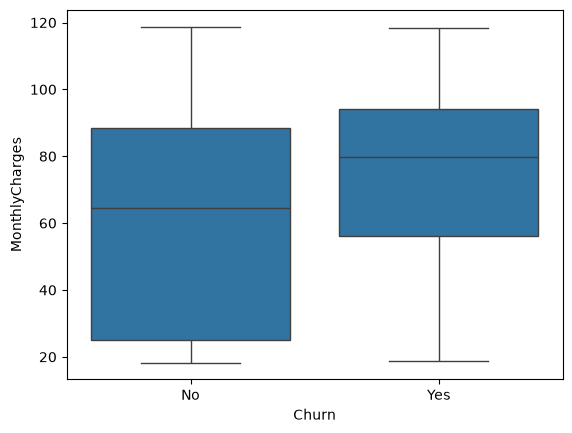

In [30]:
# Monthly charges for churned vs. retained customers
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.show()

In [31]:
df = df.replace({"No internet service" : "No","No phone service":"No"})

df["Churn"] = df["Churn"].map({"Yes":1,"No":0})
df["gender"] = df["gender"].map({"Female":0, "Male": 1})

yes_no_cols = ["Partner", "Dependents", "PhoneService", "MultipleLines",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection",
               "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]

for col in yes_no_cols:
    df[col] = df[col].map({"Yes":1 , "NO":0})

In [32]:
df = pd.get_dummies(df, columns=["InternetService", "Contract", "PaymentMethod"],
                    drop_first=True, dtype=int)

print(df.shape)
df.head()

(7032, 24)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1.0,NaN,1,NaN,NaN,NaN,1.0,NaN,...,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,NaN,NaN,34,1.0,NaN,1.0,NaN,1.0,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,NaN,NaN,2,1.0,NaN,1.0,1.0,NaN,...,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,NaN,NaN,45,NaN,NaN,1.0,NaN,1.0,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,NaN,NaN,2,1.0,NaN,NaN,NaN,NaN,...,70.70,151.65,1,1,0,0,0,0,1,0


In [33]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)

X_cv, X_test, y_cv, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

X_train, X_cv, X_test = X_train.copy(), X_cv.copy(), X_test.copy()

print(X_train.shape, X_cv.shape, X_test.shape)

(4219, 23) (1406, 23) (1407, 23)


In [34]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_cv[num_cols] = scaler.transform(X_cv[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2532,1,0,NaN,NaN,1.611180,1.0,1.0,1.0,1.0,1.0,...,NaN,1.603561,2.579933,1,0,0,1,0,0,0
6654,0,0,NaN,NaN,-1.284909,1.0,NaN,NaN,NaN,NaN,...,1.0,-0.335179,-0.984482,0,0,0,0,0,1,0
4027,1,0,1.0,1.0,-0.999379,1.0,NaN,NaN,NaN,NaN,...,NaN,-0.665177,-0.846248,0,0,0,0,0,0,0
6795,0,0,1.0,NaN,0.305901,1.0,NaN,NaN,NaN,NaN,...,NaN,-1.508322,-0.665619,0,1,0,1,0,0,1
808,1,0,NaN,NaN,1.040120,1.0,1.0,NaN,1.0,1.0,...,1.0,1.268613,1.636486,1,0,1,0,0,0,0


In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
X_train.isna().sum()[X_train.isna().sum() > 0]

Partner             2186
Dependents          2963
PhoneService         402
MultipleLines       2430
OnlineSecurity      2992
OnlineBackup        2762
DeviceProtection    2761
TechSupport         2978
StreamingTV         2589
StreamingMovies     2600
PaperlessBilling    1716
dtype: int64

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reload the original file
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Step 2: clean
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
df = df.drop(columns="customerID")

# Step 3 Part A: tidy and convert Yes/No to 1/0
df = df.replace({"No internet service": "No", "No phone service": "No"})
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["gender"] = df["gender"].map({"Female": 0, "Male": 1})

yes_no_cols = ["Partner", "Dependents", "PhoneService", "MultipleLines",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection",
               "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]
for col in yes_no_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0})

# Step 3 Part B: one-hot encoding
df = pd.get_dummies(df, columns=["InternetService", "Contract", "PaymentMethod"],
                    drop_first=True, dtype=int)

# Split and scale (Step 3 Parts C and D)
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_cv, X_test, y_cv, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

X_train, X_cv, X_test = X_train.copy(), X_cv.copy(), X_test.copy()

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_cv[num_cols] = scaler.transform(X_cv[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Checks
print("Total empty cells in df:", df.isna().sum().sum())
print("Empty cells in X_train:", X_train.isna().sum().sum())
print("Shape:", df.shape)
print(X_train.shape, X_cv.shape, X_test.shape)

Total empty cells in df: 0
Empty cells in X_train: 0
Shape: (7032, 24)
(4219, 23) (1406, 23) (1407, 23)


Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [ ]:
y_pred = model.predict(X_cv)               # 0 or 1 for each customer
y_prob = model.predict_proba(X_cv)[:, 1]   # probability of churn

print(y_pred[:10])
print(y_prob[:10].round(2))

[1 1 0 0 0 0 0 0 0 0]
[0.74 0.85 0.03 0.01 0.4  0.01 0.   0.07 0.17 0.24]


In [ ]:
from sklearn.metrics import accuracy_score

print("Train accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("CV accuracy:   ", accuracy_score(y_cv, y_pred))

Train accuracy: 0.8084854230860393
CV accuracy:    0.7965860597439545


In [ ]:
lazy_accuracy = (y_cv == 0).mean()
print("Lazy model accuracy:", lazy_accuracy)

Lazy model accuracy: 0.7339971550497866


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_cv, y_pred))
print(classification_report(y_cv, y_pred))

[[918 114]
 [172 202]]
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1032
           1       0.64      0.54      0.59       374

    accuracy                           0.80      1406
   macro avg       0.74      0.71      0.73      1406
weighted avg       0.79      0.80      0.79      1406



Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)

print("Train accuracy:", rf.score(X_train, y_train))
print("CV accuracy:   ", rf.score(X_cv, y_cv))

Train accuracy: 0.8468831476653236
CV accuracy:    0.7844950213371266


XGBoost

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                    random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)

print("Train accuracy:", xgb.score(X_train, y_train))
print("CV accuracy:   ", xgb.score(X_cv, y_cv))

Train accuracy: 0.8262621474283005
CV accuracy:    0.7901849217638691


Neural Network

In [ ]:
from sklearn.neural_network import MLPClassifier

nn = MLPClassifier(hidden_layer_sizes = (32,16), max_iter=500,
                   early_stopping=True, random_state=42)

nn.fit(X_train, y_train)

print("Train accuracy:", nn.score(X_train, y_train))
print("CV accuracy:   ", nn.score(X_cv, y_cv))

Train accuracy: 0.8080113771035791
CV accuracy:    0.7908961593172119


Compare all four models

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

models = {"Logistic Regression": model, "Random Forest": rf,
          "XGBoost": xgb, "Neural Network": nn}

results = []
for name, m in models.items():
    pred = m.predict(X_cv)
    prob = m.predict_proba(X_cv)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": m.score(X_cv, y_cv),
        "Precision": precision_score(y_cv, pred),
        "Recall": recall_score(y_cv, pred),
        "F1": f1_score(y_cv, pred),
        "ROC-AUC": roc_auc_score(y_cv, prob),
    })

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.797,0.639,0.540,0.586,0.834
1,Random Forest,0.784,0.638,0.439,0.520,0.832
2,XGBoost,0.790,0.644,0.473,0.545,0.835
3,Neural Network,0.791,0.628,0.524,0.571,0.831


In [ ]:
from sklearn.metrics import recall_score

y_prob = model.predict_proba(X_cv)[:, 1]

for t in [0.5, 0.4, 0.3]:
    pred = (y_prob >= t).astype(int)
    print("Threshold", t, "-> we catch", round(recall_score(y_cv, pred) * 100), "% of churners")

AttributeError: 'LogisticRegression' object has no attribute 'classes_'

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score

# Train the model (this was the missing step)
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Now test the thresholds
y_prob = model.predict_proba(X_cv)[:, 1]

for t in [0.5, 0.4, 0.3]:
    pred = (y_prob >= t).astype(int)
    print("Threshold", t, "-> we catch", round(recall_score(y_cv, pred) * 100), "% of churners")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [36]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
print("Model trained. Classes it learned:", model.classes_)

y_prob = model.predict_proba(X_cv)[:, 1]

for t in [0.5, 0.4, 0.3]:
    pred = (y_prob >= t).astype(int)
    print("Threshold", t, "-> we catch", round(recall_score(y_cv, pred) * 100), "% of churners")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [37]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score

# 1. Load fresh data
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# 2. Clean
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
df = df.drop(columns="customerID")

# 3. Words to numbers (replace is safe even if run twice)
df = df.replace({"No internet service": "No", "No phone service": "No"})
yes_no_cols = ["Churn", "Partner", "Dependents", "PhoneService", "MultipleLines",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection",
               "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]
for col in yes_no_cols:
    df[col] = df[col].replace({"Yes": 1, "No": 0}).astype(int)
df["gender"] = df["gender"].replace({"Female": 0, "Male": 1}).astype(int)

df = pd.get_dummies(df, columns=["InternetService", "Contract", "PaymentMethod"],
                    drop_first=True, dtype=int)

# 4. Split and scale
X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_cv, X_test, y_cv, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
X_train, X_cv, X_test = X_train.copy(), X_cv.copy(), X_test.copy()

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_cv[num_cols] = scaler.transform(X_cv[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# 5. Check for empty cells BEFORE training
print("Empty cells in X_train:", X_train.isna().sum().sum())
print("Shapes:", X_train.shape, X_cv.shape, X_test.shape)

# 6. Train and test thresholds
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
print("Model trained. Classes:", model.classes_)

y_prob = model.predict_proba(X_cv)[:, 1]
for t in [0.5, 0.4, 0.3]:
    pred = (y_prob >= t).astype(int)
    print("Threshold", t, "-> we catch", round(recall_score(y_cv, pred) * 100), "% of churners")

Empty cells in X_train: 0
Shapes: (4219, 23) (1406, 23) (1407, 23)
Model trained. Classes: [0 1]
Threshold 0.5 -> we catch 54 % of churners
Threshold 0.4 -> we catch 66 % of churners
Threshold 0.3 -> we catch 77 % of churners


In [38]:
from sklearn.metrics import precision_score, recall_score

y_prob = model.predict_proba(X_cv)[:, 1]

rows = []
for t in [0.5, 0.4, 0.3, 0.2]:
    pred = (y_prob >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Catch % (recall)": round(recall_score(y_cv, pred) * 100),
        "Correct when we say churn % (precision)": round(precision_score(y_cv, pred) * 100),
        "Customers flagged": int(pred.sum()),
    })

pd.DataFrame(rows)

,Threshold,Catch % (recall),Correct when we say churn % (precision),Customers flagged
0,0.5,54,64,316
1,0.4,66,57,432
2,0.3,77,53,546
3,0.2,85,46,696


In [39]:
chosen_threshold = 0.3
print("Chosen threshold:", chosen_threshold)

Chosen threshold: 0.3


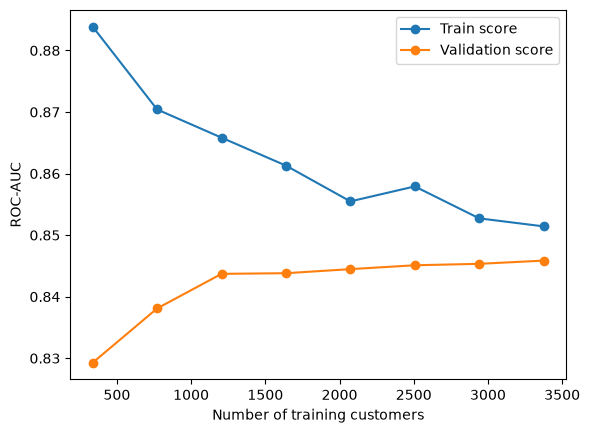

In [40]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=1000), X_train, y_train,
    cv=5, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 8))

plt.plot(sizes, train_scores.mean(axis=1), "o-", label="Train score")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="Validation score")
plt.xlabel("Number of training customers")
plt.ylabel("ROC-AUC")
plt.legend()
plt.show()

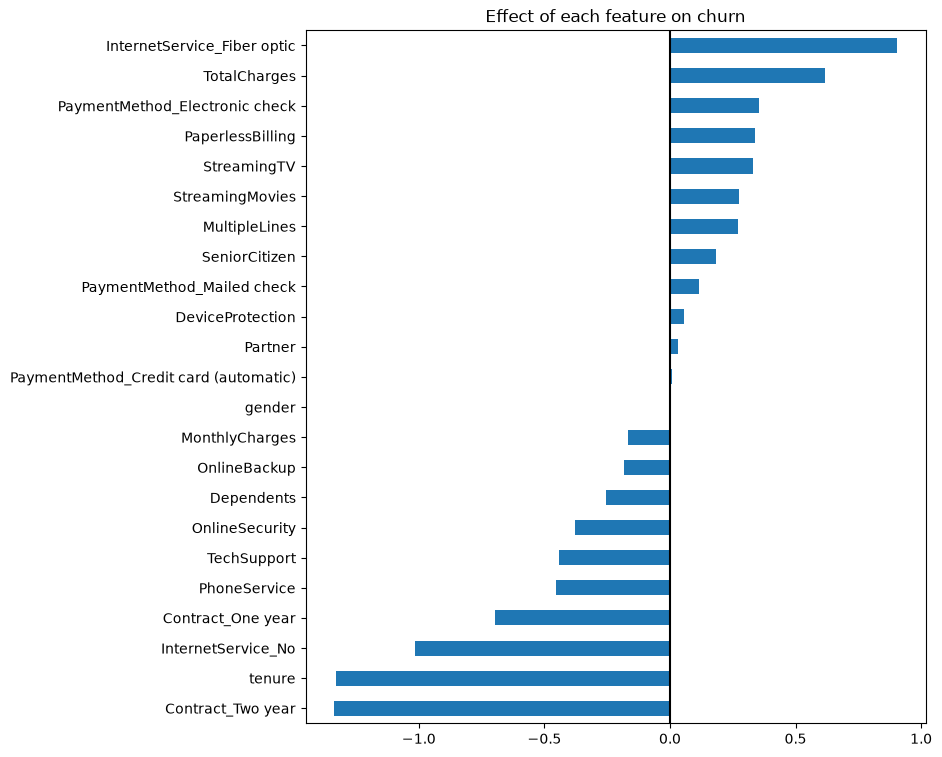

Push toward STAYING:
Contract_Two year    -1.338675
tenure               -1.327650
InternetService_No   -1.014326
Contract_One year    -0.696589
PhoneService         -0.451961
dtype: float64

Push toward LEAVING:
StreamingTV                       0.332319
PaperlessBilling                  0.337034
PaymentMethod_Electronic check    0.354134
TotalCharges                      0.616770
InternetService_Fiber optic       0.905367
dtype: float64


In [41]:
coef = pd.Series(model.coef_[0], index=X_train.columns).sort_values()

coef.plot(kind="barh", figsize=(8, 9))
plt.title("Effect of each feature on churn")
plt.axvline(0, color="black")
plt.show()

print("Push toward STAYING:")
print(coef.head(5))
print()
print("Push toward LEAVING:")
print(coef.tail(5))

In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

chosen_threshold = 0.3

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)

print("ROC-AUC:  ", round(roc_auc_score(y_test, test_prob), 3))
print("Precision:", round(precision_score(y_test, test_pred), 3))
print("Recall:   ", round(recall_score(y_test, test_pred), 3))
print("F1:       ", round(f1_score(y_test, test_pred), 3))
print()
print(confusion_matrix(y_test, test_pred))

ROC-AUC:   0.849
Precision: 0.53
Recall:    0.802
F1:        0.638

[[767 266]
 [ 74 300]]
